# Run 05: layer 32 vs layer 7 (only the layer changes)

**Run:** job 2425978. `lapa-12b-instruct`, `--split --loss_positions words --layer_id 32 --layer_ids 30,31,32 --beta 1 --lr 5e-4 --alpha 5`, 129 steps.

Identical to run 04 (`../04/04.ipynb`) except for the layer:

| | run 04 | run 05 |
|---|---|---|
| hooked layer (loss computed here) | 7 (≈ 15% depth) | **32** (≈ 67% of 48 layers) |
| trained `down_proj` layers | 5, 6, 7 | **30, 31, 32** |
| data, β, lr, α, positions | same | same (identical batches at every step) |

**Question:** at a deeper layer, token activations carry more context. Does that (a) make the edit **selective** (forget changes more than retain), and/or (b) change **how** the loss is lowered (shrinking vs rotation)?

Adaptive RMU makes the two layers comparable: with β = 1 the target is always as long as each token's own activation, so k, cos(a, u) and the *relative* loss drop mean the same thing at both layers, even though the raw losses are in different units.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

H = 3840
ALPHA = 5.0

d = pd.read_csv("05logs.csv")
run04 = pd.read_csv("../04/04logs.csv")

print(f"{len(d)} steps, any NaN: {d.drop(columns='forget_ids').isna().any().any()}")
print(f"forget batches identical to run 04: {(d.forget_ids.values == run04.forget_ids.values).all()}")

129 steps, any NaN: False
forget batches identical to run 04: True


## Scale of the activations

Layer 32 activations are much longer than at layer 7. A quick check of the "no change" formula from run 01, $(1 + \beta^2)\lVert a_0\rVert^2 / H$, at step 0:

In [2]:
for name, df in [("layer 7 (run 04)", run04), ("layer 32 (run 05)", d)]:
    a0 = df.target_word_norm.iloc[0]
    print(f"{name}: word norm {a0:9,.0f}   BOS/other {df.forget_other_norm.iloc[0]:9,.0f}   "
          f"formula {2 * a0**2 / H:12,.0f}   logged {df.unlearn_loss_frozen.iloc[0]:12,.0f}")

layer 7 (run 04): word norm     2,430   BOS/other    35,314   formula        3,076   logged        3,133
layer 32 (run 05): word norm    64,752   BOS/other   284,649   formula    2,183,766   logged    2,234,729


## Summary per block of steps

In [3]:
cols = ["forget_norm_ratio", "retain_norm_ratio", "forget_cos_u", "retain_cos_u",
        "unlearn_cosine_sim", "retain_cosine_sim", "forget_cos_min"]
blocks = d.groupby(pd.cut(d.step, [-1, 0, 30, 60, 90, 129]), observed=True)[cols].mean()
blocks.index = ["step 0", "1-30", "31-60", "61-90", "91-128"]
blocks["relative drop"] = (1 - d.unlearn_loss / d.unlearn_loss_frozen).groupby(
    pd.cut(d.step, [-1, 0, 30, 60, 90, 129]), observed=True).mean().values
blocks.round(4)

,forget_norm_ratio,retain_norm_ratio,forget_cos_u,retain_cos_u,unlearn_cosine_sim,retain_cosine_sim,forget_cos_min,relative drop
step 0,1.0000,1.0000,0.0077,0.0068,1.0000,1.0000,1.0000,0.0000
1-30,0.8605,0.8683,0.1511,0.1495,0.9794,0.9797,0.9771,0.2509
31-60,0.8607,0.8639,0.1821,0.1801,0.9799,0.9802,0.9769,0.2812
61-90,0.8528,0.8579,0.1900,0.1843,0.9789,0.9799,0.9747,0.2947
91-128,0.8550,0.8620,0.1924,0.1858,0.9775,0.9788,0.9706,0.2959


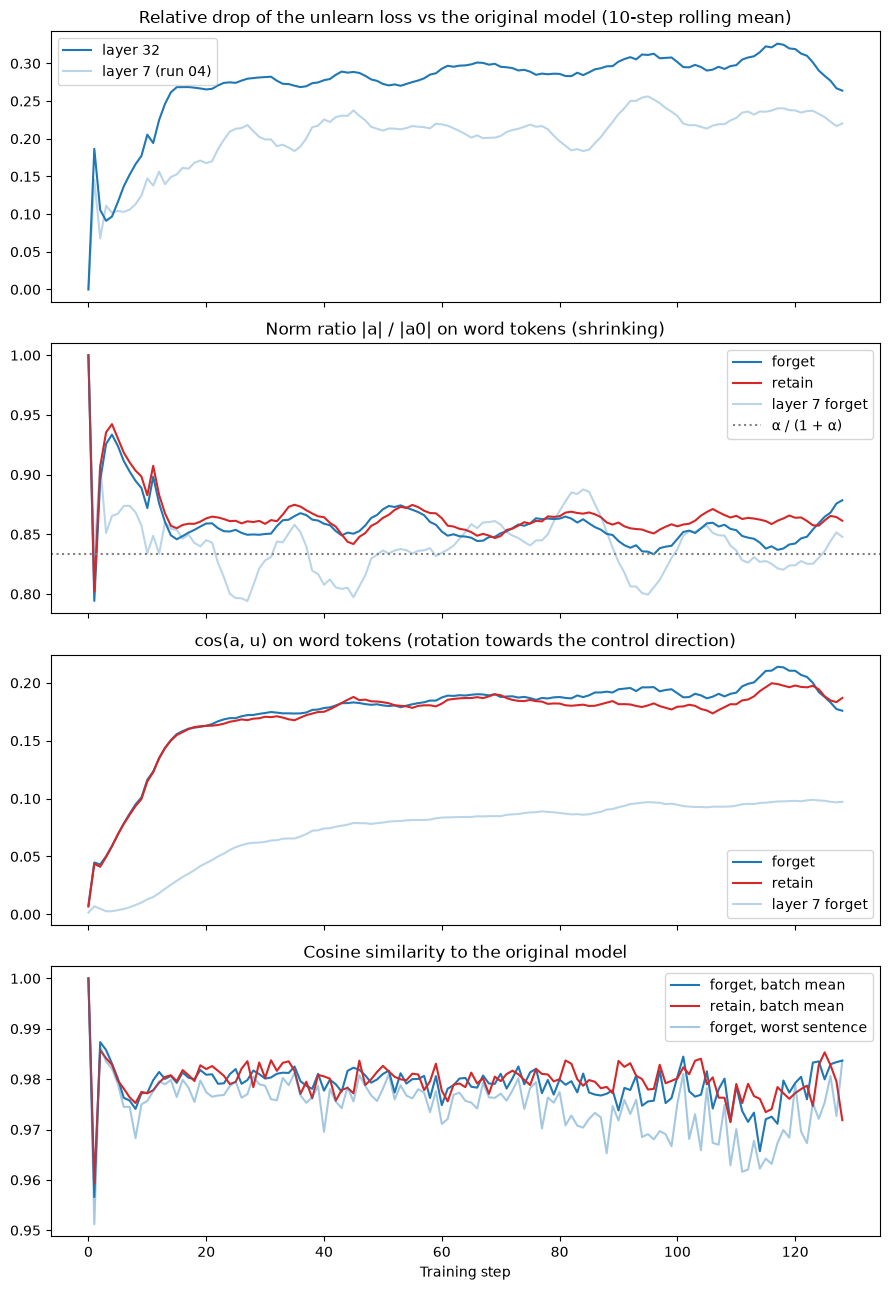

In [4]:
def smooth(s):
    return s.rolling(10, min_periods=1).mean()

FORGET, RETAIN = "tab:blue", "tab:red"
fig, axes = plt.subplots(4, 1, figsize=(9, 13), sharex=True)

ax = axes[0]
ax.plot(d.step, smooth(1 - d.unlearn_loss / d.unlearn_loss_frozen), label="layer 32", color=FORGET)
ax.plot(run04.step, smooth(1 - run04.unlearn_loss / run04.unlearn_loss_frozen),
        label="layer 7 (run 04)", color=FORGET, alpha=0.3)
ax.set_title("Relative drop of the unlearn loss vs the original model (10-step rolling mean)")
ax.legend()

ax = axes[1]
ax.plot(d.step, smooth(d.forget_norm_ratio), label="forget", color=FORGET)
ax.plot(d.step, smooth(d.retain_norm_ratio), label="retain", color=RETAIN)
ax.plot(run04.step, smooth(run04.forget_norm_ratio), label="layer 7 forget", color=FORGET, alpha=0.3)
ax.axhline(ALPHA / (1 + ALPHA), color="grey", ls=":", label="α / (1 + α)")
ax.set_title("Norm ratio |a| / |a0| on word tokens (shrinking)")
ax.legend()

ax = axes[2]
ax.plot(d.step, smooth(d.forget_cos_u), label="forget", color=FORGET)
ax.plot(d.step, smooth(d.retain_cos_u), label="retain", color=RETAIN)
ax.plot(run04.step, smooth(run04.forget_cos_u), label="layer 7 forget", color=FORGET, alpha=0.3)
ax.set_title("cos(a, u) on word tokens (rotation towards the control direction)")
ax.legend()

ax = axes[3]
ax.plot(d.step, d.unlearn_cosine_sim, label="forget, batch mean", color=FORGET)
ax.plot(d.step, d.retain_cosine_sim, label="retain, batch mean", color=RETAIN)
ax.plot(d.step, d.forget_cos_min, label="forget, worst sentence", color=FORGET, alpha=0.4)
ax.set_title("Cosine similarity to the original model")
ax.set_xlabel("Training step")
ax.legend()

fig.tight_layout()
fig.savefig("05_layer32_vs_layer7.png", dpi=120)

## 1. Layer 32 vs layer 7, last 30 steps

In [5]:
def summary(df, name):
    late = df.iloc[-30:]
    k, cos_u = late.forget_norm_ratio, late.forget_cos_u
    shrink, rotation = ((1 - k**2) / 2).mean(), (k * cos_u).mean()
    return {
        "run": name,
        "forget k": k.mean(),
        "retain k": late.retain_norm_ratio.mean(),
        "forget cos(a,u)": cos_u.mean(),
        "retain cos(a,u)": late.retain_cos_u.mean(),
        "corr cos(a,u) f/r": df.forget_cos_u.corr(df.retain_cos_u),
        "relative drop": (1 - late.unlearn_loss / late.unlearn_loss_frozen).mean(),
        "shrinking term": shrink,
        "rotation term": rotation,
        "rotation share": rotation / (shrink + rotation),
    }

pd.DataFrame([summary(run04, "layer 7 (run 04)"), summary(d, "layer 32 (run 05)")]).set_index("run").T.round(3)

run,layer 7 (run 04),layer 32 (run 05)
forget k,0.839,0.858
retain k,0.845,0.864
"forget cos(a,u)",0.096,0.193
"retain cos(a,u)",0.095,0.188
"corr cos(a,u) f/r",0.981,0.869
relative drop,0.227,0.294
shrinking term,0.147,0.131
rotation term,0.080,0.165
rotation share,0.353,0.556


The shrinking and rotation terms come from the same decomposition as before (β = 1, $\cos(a_0, u) \approx 0$): relative drop ≈ $\frac{1-k^2}{2} + k\cos(a,u)$, shrinking counted first.

In [6]:
late = d.iloc[-30:]
print(f"last 30 steps: forget rotated further than retain in {(late.forget_cos_u > late.retain_cos_u).mean():.0%}, "
      f"shrank more in {(late.forget_norm_ratio < late.retain_norm_ratio).mean():.0%} of steps")
gap = d.unlearn_cosine_sim - d.retain_cosine_sim
print(f"median forget - retain cosine-to-original gap, last 30 steps: {gap.iloc[-30:].median():.5f}")

last 30 steps: forget rotated further than retain in 57%, shrank more in 53% of steps
median forget - retain cosine-to-original gap, last 30 steps: -0.00018


## Conclusions

1. **The deeper layer changes *how* the loss is lowered: for the first time, rotation is the bigger part.** At layer 32 the activations rotate about twice as far towards $u$ (cos ≈ 0.19, ≈ 79°, vs 0.096 at layer 7) and shrink less (k ≈ 0.86 vs 0.84). Rotation is ≈ 56% of the drop (layer 7: ≈ 35%). The total drop is also larger: ≈ 29% vs ≈ 23%. So at layer 32 the edit is closer to what RMU is meant to do: misdirection rather than weakening.
2. **It is still not selective.** Retain rotates (0.188 vs 0.193) and shrinks (0.864 vs 0.858) almost exactly like forget. The cosine-to-original gap is ≈ 0, and forget is ahead in only about half of the last 30 steps, which is no better than chance. The forget/retain correlation of cos(a, u) is lower (0.87 vs 0.98), but that's mostly because the curves are flatter after step 30, so there's less shared trend to correlate. It's not a real separation.
3. **Most of the change happens early.** The jolt at step 1 (k = 0.59, then back to ≈ 1.1 at step 2) is followed by fast rotation up to step ≈ 30. After that it only creeps up (0.168 → 0.192).
4. **The balance k ≈ α/(1+α) = 0.83 no longer fits as well** (k ≈ 0.86). That's expected: the formula ignores rotation, and here rotation does more of the work.
5. **Scale:** word activations are ≈ 65,000 long at layer 32 (≈ 27× layer 7), and BOS ≈ 285,000. Adaptive β handled this with no retuning, and the "no change" formula matches the logged baseline to within ≈ 2%.

**Summary of the experiments so far:** neither the data design (twins vs split, run 04) nor the layer (7 vs 32, run 05) makes the edit selective. The layer changes the *mechanism* (more rotation, less shrinking), but forget and retain still change together. Next ideas: a cosine loss (removes the shrinking shortcut completely), and measuring the edit on non-gender text to see whether it's gender-specific at all.